<a href="https://colab.research.google.com/github/Saransh-Basu-01/50-Ml-Projects-to-understand-LLMs/blob/main/Project_27_Impact_of_Layer_Specific_Noise_and_Scaling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

import numpy as np
import matplotlib.pyplot as plt

import torch

from transformers import AutoModelForCausalLM, AutoTokenizer

# Part_1:Model,Tokens,and Clean Activations

## Task_1:
- Import GPT-2-large and its tokenizer, and set the flag for outputting
hidden states to True. Switch the model to eval mode and optionally
move it to the GPU. Report the number of transformer layers based
on information available in model.config.
Tokenize the sentence “Pay no attention to that man behind
the”. Do you know what word should come next?
It’s “curtain.” Find the token index for the word “ curtain”
(with leading space), and print out the tokenization

In [3]:
tokenizer = AutoTokenizer.from_pretrained('gpt2')
model = AutoModelForCausalLM.from_pretrained('gpt2-large',output_hidden_states=True)
model.eval()

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/666 [00:00<?, ?B/s]

... (2 outputs left out)

[transformers] The following generation flags are not valid and may be ignored: ['output_hidden_states']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Loading weights:   0%|          | 0/436 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 1280)
    (wpe): Embedding(1024, 1280)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-35): 36 x GPT2Block(
        (ln_1): LayerNorm((1280,), eps=1e-05, elementwise_affine=True, bias=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=3840, nx=1280)
          (c_proj): Conv1D(nf=1280, nx=1280)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((1280,), eps=1e-05, elementwise_affine=True, bias=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=5120, nx=1280)
          (c_proj): Conv1D(nf=1280, nx=5120)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((1280,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (lm_head): Linear(in_features=1280, out_features=50257, bias=False)
)

In [4]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device);

In [5]:
model.config

GPT2Config {
  "activation_function": "gelu_new",
  "add_cross_attention": false,
  "architectures": [
    "GPT2LMHeadModel"
  ],
  "attn_pdrop": 0.1,
  "bos_token_id": 50256,
  "dtype": "float32",
  "embd_pdrop": 0.1,
  "eos_token_id": 50256,
  "initializer_range": 0.02,
  "layer_norm_epsilon": 1e-05,
  "model_type": "gpt2",
  "n_ctx": 1024,
  "n_embd": 1280,
  "n_head": 20,
  "n_inner": null,
  "n_layer": 36,
  "n_positions": 1024,
  "output_hidden_states": true,
  "pad_token_id": null,
  "reorder_and_upcast_attn": false,
  "resid_pdrop": 0.1,
  "scale_attn_by_inverse_layer_idx": false,
  "scale_attn_weights": true,
  "summary_activation": null,
  "summary_first_dropout": 0.1,
  "summary_proj_to_labels": true,
  "summary_type": "cls_index",
  "summary_use_proj": true,
  "task_specific_params": {
    "text-generation": {
      "do_sample": true,
      "max_length": 50
    }
  },
  "tie_word_embeddings": true,
  "transformers_version": "5.22.1",
  "use_cache": true,
  "vocab_size": 502

In [6]:
print(f'This LLM has {model.config.n_layer} transformer layers.')

This LLM has 36 transformer layers.


In [7]:

text = 'Pay no attention to that man behind the'
tokens =tokenizer.encode(text,return_tensors='pt')
target_token =tokenizer.encode(" curtain",return_tensors='pt')[0]

for t in tokens[0]:
  print(f"Token {t} is '{tokenizer.decode(t)}'")

Token 19197 is 'Pay'
Token 645 is ' no'
Token 3241 is ' attention'
Token 284 is ' to'
Token 326 is ' that'
Token 582 is ' man'
Token 2157 is ' behind'
Token 262 is ' the'


## Task_2
- Run a forward pass to get model outputs. Name the output variable
outputs_clean. These data will be used as a “clean” baseline
reference against which to compare the impact of the manipulations.
Find and print the token with the largest output logit, and
store the log-softmax probability of the logit for “ curtain”.
Show all logits in a scatter plot, and indicate the maximum
using dashed lines, as in Figure 5.20.

In [8]:
with torch.no_grad(): # ~8s on CPU, <1s on GPU
  outputs_clean = model(tokens.to(device))

outputs_clean.hidden_states[0].shape

torch.Size([1, 8, 1280])

In [9]:
logsm = outputs_clean.logits[0,-1,:].log_softmax(dim=-1)
log_sm_target_clean = logsm[target_token].item()

nextword_clean = torch.argmax(logsm)
print(f'Next word is "{tokenizer.decode(nextword_clean)}" (token index {nextword_clean}) with {np.exp(log_sm_target_clean):.2%} probability.')

Next word is " curtain" (token index 29461) with 38.84% probability.


In [10]:
outputs_clean.hidden_states[36].shape

torch.Size([1, 8, 1280])

In [11]:
outputs_clean.logits.shape

torch.Size([1, 8, 50257])

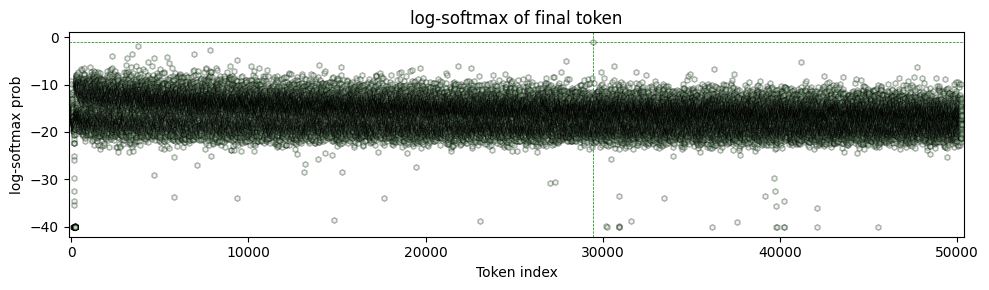

In [12]:

plt.figure(figsize=(10,3))

plt.axhline(log_sm_target_clean,color='g',linestyle='--',linewidth=.5)
plt.axvline(target_token,color='g',linestyle='--',linewidth=.5)

plt.plot(logsm.cpu(),'kh',markerfacecolor=[.7,.9,.7,.3],markersize=4)
plt.gca().set(xlabel='Token index',ylabel='log-softmax prob',
              title='log-softmax of final token',xlim=[-150,tokenizer.vocab_size+150])

plt.tight_layout()
plt.show()

# Part 2: Hook to inject noise

## Task_1:
- Write a hook function that adds noise to the transformer out
put vectors. Give the hook functions interpretable names, like
implant_noise_hook and noise_hook. The noise should be nor
mally distributed random numbers with a standard deviation equal
to half that of the layer-specific hidden-state vectors. Implant the
hook into all transformer layers while allowing only one layer at a
time to be manipulated.
Run the tokens through the model while adding noise only to
layer 15. Name the output variable outputs_noise to differentiate
it from the “clean” model you ran in Part 1.
In a for-loop over the hidden-state layers, calculate and visual
ize the matrix norm of the difference of the hidden-state activations
between the two versions of the model. Include a vertical dashed line
to indicate the manipulated layer. See Figure 5.21.
Finally, calculate and print the predicted new token. Use de
terministic token selection

In [13]:
# hooking functions
def implant_noise_hook(layer_number):
  def noise_hook(module,input,hidden):

    # only change one layer
    if layer_number == layer2noise:

      # generate a matrix of noise
      h_std = hidden.std() / 2
      noise = torch.randn_like(hidden)*h_std

      # add that noise to the hidden states
      hidden += noise
      # print(f'Changed layer {layer_number} with noise')

    return hidden
  return noise_hook


# loop over layers and do surgery
handles = []
for layeri in range(model.config.n_layer):
  baselayer = model.transformer.h[layeri]
  h = baselayer.register_forward_hook(implant_noise_hook(layeri))
  handles.append(h)

In [14]:

# test with one layer
layer2noise = 15

with torch.no_grad():
  outputs_noise = model(tokens.to(device))

outputs_noise.hidden_states[0].shape

torch.Size([1, 8, 1280])

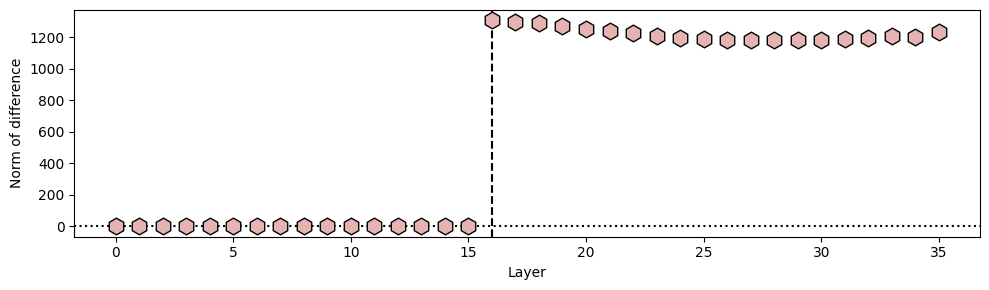

In [15]:
# initialize
diffnorms = torch.zeros(model.config.n_layer)

# loop over layers
for layeri in range(model.config.n_layer):

  # extract hidden states for this layer
  hs_c = outputs_clean.hidden_states[layeri].cpu()
  hs_n = outputs_noise.hidden_states[layeri].cpu()

  # norm of difference matrix
  diffnorms[layeri] = torch.norm(hs_c-hs_n)

# and plot
plt.figure(figsize=(10,3))
plt.plot(diffnorms,'kh',markerfacecolor=[.9,.7,.7],markersize=12)
plt.axvline(layer2noise+1,color='k',linestyle='--',zorder=-10)
plt.axhline(0,color='k',linestyle=':',zorder=-10)
plt.gca().set(xlabel='Layer',ylabel='Norm of difference')

plt.tight_layout()
plt.show()

In [16]:

# predicted next token and its probability
max_logit = torch.argmax(outputs_noise.logits[0,-1,:])
log_sm = outputs_noise.logits[0,-1,:].softmax(dim=-1)

print(f' Clean model: next token is "{tokenizer.decode(nextword_clean)}" with {np.exp(log_sm_target_clean):.2%} probability.')
print(f'Noised model: next token is "{tokenizer.decode(max_logit)}" with {log_sm[max_logit].item():.2%} probability.')

 Clean model: next token is " curtain" with 38.84% probability.
Noised model: next token is " P" with 9.13% probability.


# Part_3:Impacts of layer-specific noising

## Task_1:
- In a for-loop over all transformer layers, run the same tokens through
the model but change the value of the layer2noise variable at
each iteration. To be clear: Each iteration in the for-loop involves
directly manipulating only one layer, and all layers have their
activations manipulated in different loop iterations. Calculate the
log-softmax probability of the final token, and store the log-softmax of
the target token (“ curtain”) and of the token with the largest logit.
Visualize the results as in Figure 5.22 (note the matching y
axis limits). Print out the predicted text after noisifiying each layer,
e.g.,
L27: Pay no attention to that man behind the“ next”
Finally, remove all the hooks from the model. If you installed
the hooks without saving the handles, you’ll need to re-import the
model for Part 4.